<a href="https://colab.research.google.com/github/ShaikSiddiqAli/24pa1a45b1-source.github.io/blob/main/internalproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#step 1 -DATASET READING


In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv("/content/sales_transactions_regression.csv")
df

,transaction_id,region,product_id,product_id.1,sales_amount,date,units_sold,unit_price,discount_pct,store_id,product_id.2,product_id.3
0,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
1,T50001,East,394.0,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3,394.0,394.0
2,T50002,West,446.0,446.0,323.4660,2024-01-03,4.0,92.95,NaN,S2,446.0,446.0
3,T50003,South,136.0,136.0,3439.5648,2024-01-04,8.0,438.72,NaN,S4,136.0,136.0
4,T50004,South,287.0,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4,287.0,287.0
...,...,...,...,...,...,...,...,...,...,...,...,...
255,T50027,North,141.0,141.0,1831.4256,2024-01-28,4.0,497.67,0.08,S2,141.0,141.0
256,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
257,T50125,SOUTH,115.0,115.0,426.1950,2024-05-05,2.0,387.45,0.45,S1,115.0,115.0
258,T50190,East,NaN,NaN,965.5788,2024-07-09,4.0,271.23,0.11,S2,NaN,NaN


#step 2 - DATA PREPROCESSING


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  249 non-null    object 
 1   region          245 non-null    object 
 2   product_id      239 non-null    float64
 3   product_id.1    239 non-null    float64
 4   sales_amount    249 non-null    float64
 5   date            248 non-null    object 
 6   units_sold      241 non-null    float64
 7   unit_price      239 non-null    float64
 8   discount_pct    244 non-null    float64
 9   store_id        249 non-null    object 
 10  product_id.2    239 non-null    float64
 11  product_id.3    239 non-null    float64
dtypes: float64(8), object(4)
memory usage: 24.5+ KB


#step 3 - checking null values

In [4]:
df.isnull().sum()

,0
transaction_id,11
region,15
product_id,21
product_id.1,21
sales_amount,11
date,12
units_sold,19
unit_price,21
discount_pct,16
store_id,11


In [5]:
print("Duplicates:",df.duplicated().sum())


Duplicates: 10


In [7]:
df.shape

(260, 12)

#step 4 -Finding duplicates


In [12]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates()
df = df.drop(columns=[
    'product_id.1',
    'product_id.2',
    'product_id.3'
], errors='ignore')
print("Shape after cleaning:", df.shape)
df

Duplicates before: 0
Shape after cleaning: (250, 9)


,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
0,T50000,West,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2
1,T50001,East,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3
2,T50002,West,446.0,323.4660,2024-01-03,4.0,92.95,NaN,S2
3,T50003,South,136.0,3439.5648,2024-01-04,8.0,438.72,NaN,S4
4,T50004,South,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4
...,...,...,...,...,...,...,...,...,...
245,T50245,West,391.0,1687.2426,2024-09-02,9.0,217.99,NaN,S4
246,T50246,Nort,365.0,492.7580,NaN,2.0,NaN,0.30,S4
247,T50247,Wet,346.0,1131.5192,2024-09-04,7.0,218.44,0.26,S4
248,T50248,South,NaN,927.3030,2024-09-05,5.0,199.42,0.07,S1


#step 5 -dupliacated sum



In [13]:
df.duplicated().sum()

np.int64(0)

#step 6 -Handling inconsistent data


In [15]:
df['region'] = df['region'].str.strip().str.title()
region_mapping = {
    'Wet': 'West',
    'Wst': 'West',
    'Wes': 'West',
    'Est': 'West',
    'Eat': 'East',
    'Eas': 'East',
    'Ast': 'East',
    'Soth': 'South',
    'Nort': 'North',
    'Noth': 'North',
    'Norh': 'North',
    'Nrth': 'North',
    'Orth': 'North'
}
df['region'] = df['region'].replace(region_mapping)
print(df['region'].value_counts(dropna=False))
df

region
West     65
East     62
North    59
South    50
NaN      14
Name: count, dtype: int64


,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
0,T50000,West,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2
1,T50001,East,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3
2,T50002,West,446.0,323.4660,2024-01-03,4.0,92.95,NaN,S2
3,T50003,South,136.0,3439.5648,2024-01-04,8.0,438.72,NaN,S4
4,T50004,South,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4
...,...,...,...,...,...,...,...,...,...
245,T50245,West,391.0,1687.2426,2024-09-02,9.0,217.99,NaN,S4
246,T50246,North,365.0,492.7580,NaN,2.0,NaN,0.30,S4
247,T50247,West,346.0,1131.5192,2024-09-04,7.0,218.44,0.26,S4
248,T50248,South,NaN,927.3030,2024-09-05,5.0,199.42,0.07,S1


#Step 7 - key restrictuing

In [49]:
df['store_id'] = df['store_id'].str.strip().str.upper()
store_mapping = {
    '1': 'S1',
    '2': 'S2',
    '3': 'S3',
    '4': 'S4'
}
df['store_id'] = df['store_id'].replace(store_mapping)
df

,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
0,T50000,West,426,965.0340,2024-01-01,6.0,233.10,0.31,S2
1,T50001,East,394,992.0770,2024-01-02,5.0,241.97,0.18,S3
2,T50002,West,446,323.4660,2024-01-03,4.0,92.95,0.13,S2
3,T50003,South,136,3439.5648,2024-01-04,8.0,438.72,0.02,S4
4,T50004,South,287,1207.0240,2024-01-05,7.0,265.28,0.35,S4
...,...,...,...,...,...,...,...,...,...
245,T50245,West,391,1687.2426,2024-09-02,9.0,217.99,0.14,S4
246,T50246,North,365,492.7580,2024-09-02,2.0,351.97,0.30,S4
247,T50247,West,346,1131.5192,2024-09-04,7.0,218.44,0.26,S4
248,T50248,South,313,927.3030,2024-09-05,5.0,199.42,0.07,S1


In [18]:
df.isna().sum()

,0
transaction_id,10
region,14
product_id,19
sales_amount,11
date,12
units_sold,17
unit_price,21
discount_pct,15
store_id,10


#step 8 Handling Null Values


In [20]:
df.loc[df['unit_price'].isna(), 'unit_price'] = (
    df['sales_amount'] /
    (df['units_sold'] * (1 - df['discount_pct']))
)
df

,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
0,T50000,West,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2
1,T50001,East,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3
2,T50002,West,446.0,323.4660,2024-01-03,4.0,92.95,NaN,S2
3,T50003,South,136.0,3439.5648,2024-01-04,8.0,438.72,NaN,S4
4,T50004,South,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4
...,...,...,...,...,...,...,...,...,...
245,T50245,West,391.0,1687.2426,2024-09-02,9.0,217.99,NaN,S4
246,T50246,North,365.0,492.7580,NaN,2.0,351.97,0.30,S4
247,T50247,West,346.0,1131.5192,2024-09-04,7.0,218.44,0.26,S4
248,T50248,South,NaN,927.3030,2024-09-05,5.0,199.42,0.07,S1


In [22]:
df.isna()

,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
245,False,False,False,False,False,False,False,False,False
246,False,False,False,False,True,False,False,False,False
247,False,False,False,False,False,False,False,False,False
248,False,False,True,False,False,False,False,False,False


In [27]:
df["product_id"] = df["product_id"].fillna(df["product_id"].median())
df["product_id"].isna().sum()

np.int64(0)

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 0 to 249
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  240 non-null    object 
 1   region          236 non-null    object 
 2   product_id      250 non-null    float64
 3   sales_amount    246 non-null    float64
 4   date            238 non-null    object 
 5   units_sold      246 non-null    float64
 6   unit_price      245 non-null    float64
 7   discount_pct    249 non-null    float64
 8   store_id        240 non-null    object 
dtypes: float64(5), object(4)
memory usage: 27.6+ KB


In [29]:
df.isna().sum()

,0
transaction_id,10
region,14
product_id,0
sales_amount,4
date,12
units_sold,4
unit_price,5
discount_pct,1
store_id,10


In [ ]:
df["product_id"] = df["product_id"].fillna(df["product_id"].median())


In [31]:
df['transaction_id'] = df['transaction_id'].astype('string')
missing = df['transaction_id'].isna()

df.loc[missing, 'transaction_id'] = [
    f'TXN_NEW_{i}'
    for i in range(1, missing.sum() + 1)
]
df.isna().sum()

,0
transaction_id,0
region,14
product_id,0
sales_amount,4
date,12
units_sold,4
unit_price,5
discount_pct,1
store_id,10


#step 9 -filling missing values column wise

In [33]:

df['units_sold'] = df['units_sold'].fillna(
    df['units_sold'].median()
)
df['unit_price'] = df['unit_price'].fillna(
    df['unit_price'].median()
)
df['discount_pct'] = df['discount_pct'].fillna(
    df['discount_pct'].median()
)
df['region'] = df['region'].fillna('Unknown')
df['store_id'] = df['store_id'].fillna('Unknown')
df.isna().sum()

,0
transaction_id,0
region,0
product_id,0
sales_amount,4
date,12
units_sold,0
unit_price,0
discount_pct,0
store_id,0


In [35]:
df

,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
0,T50000,West,426.000000,965.0340,2024-01-01,6.0,233.10,0.31,S2
1,T50001,East,394.000000,992.0770,2024-01-02,5.0,241.97,0.18,S3
2,T50002,West,446.000000,323.4660,2024-01-03,4.0,92.95,0.13,S2
3,T50003,South,136.000000,3439.5648,2024-01-04,8.0,438.72,0.02,S4
4,T50004,South,287.000000,1207.0240,2024-01-05,7.0,265.28,0.35,S4
...,...,...,...,...,...,...,...,...,...
245,T50245,West,391.000000,1687.2426,2024-09-02,9.0,217.99,0.14,S4
246,T50246,North,365.000000,492.7580,NaN,2.0,351.97,0.30,S4
247,T50247,West,346.000000,1131.5192,2024-09-04,7.0,218.44,0.26,S4
248,T50248,South,313.675325,927.3030,2024-09-05,5.0,199.42,0.07,S1


#Step 9 - converting datatypes

In [36]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['transaction_id'] = df['transaction_id'].astype('string')
df['region'] = df['region'].astype('category')
df['store_id'] = df['store_id'].astype('category')

#step 10 -filling missing values in date column using forward fill

In [39]:
df['date'] = pd.to_datetime(df['date'],errors = "coerce")
df["date"] = df["date"].ffill()
df

,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
0,T50000,West,426.000000,965.0340,2024-01-01,6.0,233.10,0.31,S2
1,T50001,East,394.000000,992.0770,2024-01-02,5.0,241.97,0.18,S3
2,T50002,West,446.000000,323.4660,2024-01-03,4.0,92.95,0.13,S2
3,T50003,South,136.000000,3439.5648,2024-01-04,8.0,438.72,0.02,S4
4,T50004,South,287.000000,1207.0240,2024-01-05,7.0,265.28,0.35,S4
...,...,...,...,...,...,...,...,...,...
245,T50245,West,391.000000,1687.2426,2024-09-02,9.0,217.99,0.14,S4
246,T50246,North,365.000000,492.7580,2024-09-02,2.0,351.97,0.30,S4
247,T50247,West,346.000000,1131.5192,2024-09-04,7.0,218.44,0.26,S4
248,T50248,South,313.675325,927.3030,2024-09-05,5.0,199.42,0.07,S1


In [40]:
df.isna().sum()

,0
transaction_id,0
region,0
product_id,0
sales_amount,4
date,0
units_sold,0
unit_price,0
discount_pct,0
store_id,0


In [41]:
df["sales_amount"] = df["sales_amount"].fillna(df["sales_amount"].median())
df.isna().sum()

,0
transaction_id,0
region,0
product_id,0
sales_amount,0
date,0
units_sold,0
unit_price,0
discount_pct,0
store_id,0


#Step 11 - final validation


In [42]:
print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:")
print(df.duplicated().sum())
print("\nData Types:")
print(df.dtypes)
print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (250, 9)

Missing Values:
transaction_id    0
region            0
product_id        0
sales_amount      0
date              0
units_sold        0
unit_price        0
discount_pct      0
store_id          0
dtype: int64

Duplicate Rows:
0

Data Types:
transaction_id    string[python]
region                  category
product_id               float64
sales_amount             float64
date              datetime64[ns]
units_sold               float64
unit_price               float64
discount_pct             float64
store_id                category
dtype: object

Statistical Summary:
       product_id  sales_amount                        date  units_sold  \
count  250.000000    250.000000                         250  250.000000   
mean   313.675325    975.121143  2024-05-04 10:50:52.800000    5.192000   
min    103.000000     14.792400         2024-01-01 00:00:00    1.000000   
25%    224.250000    372.564900         2024-03-03 06:00:00    3.000000   
50%    319.500000    732.4

In [43]:
print(df['product_id'].head(10))
print(df['product_id'].dtype)

0    426.0
1    394.0
2    446.0
3    136.0
4    287.0
5    436.0
6    487.0
7    122.0
8    497.0
9    360.0
Name: product_id, dtype: float64
float64


In [44]:
df['product_id'] = df['product_id'].astype(int)

In [45]:
print("Product ID datatype:", df['product_id'].dtype)
print(df['product_id'].head(10))

Product ID datatype: int64
0    426
1    394
2    446
3    136
4    287
5    436
6    487
7    122
8    497
9    360
Name: product_id, dtype: int64


#Data Info

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 0 to 249
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   transaction_id  250 non-null    string        
 1   region          250 non-null    category      
 2   product_id      250 non-null    int64         
 3   sales_amount    250 non-null    float64       
 4   date            250 non-null    datetime64[ns]
 5   units_sold      250 non-null    float64       
 6   unit_price      250 non-null    float64       
 7   discount_pct    250 non-null    float64       
 8   store_id        250 non-null    category      
dtypes: category(2), datetime64[ns](1), float64(4), int64(1), string(1)
memory usage: 24.6 KB


In [48]:
df.duplicated().sum()

np.int64(0)

#CHECKING and FIXING OUTLIERS

In [63]:
numeric_cols = [
    'sales_amount',
    'units_sold',
    'unit_price',
    'discount_pct'
]
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]
    print(f"\nColumn: {col}")
    print("Outliers:", len(outliers))
    print("Lower limit:", lower)
    print("Upper limit:", upper)


Column: sales_amount
Outliers: 7
Lower limit: -1144.18065
Upper limit: 2900.47415

Column: units_sold
Outliers: 0
Lower limit: -3.0
Upper limit: 13.0

Column: unit_price
Outliers: 0
Lower limit: -212.60125000000002
Upper limit: 712.92875

Column: discount_pct
Outliers: 0
Lower limit: -0.21000000000000008
Upper limit: 0.6700000000000002


In [64]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = df[col].clip(
        lower=lower,
        upper=upper
    )
print("Outliers capped successfully!")

Outliers capped successfully!


In [65]:
numeric_cols = [
    'sales_amount',
    'units_sold',
    'unit_price',
    'discount_pct'
]
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]
    print(f"\nColumn: {col}")
    print("Outliers:", len(outliers))
    print("Lower limit:", lower)
    print("Upper limit:", upper)


Column: sales_amount
Outliers: 0
Lower limit: -1144.18065
Upper limit: 2900.47415

Column: units_sold
Outliers: 0
Lower limit: -3.0
Upper limit: 13.0

Column: unit_price
Outliers: 0
Lower limit: -212.60125000000002
Upper limit: 712.92875

Column: discount_pct
Outliers: 0
Lower limit: -0.21000000000000008
Upper limit: 0.6700000000000002


#Converting Cleaned dataset into new csv file

In [66]:
df.to_csv("Cleaned_Sales_csv",index = False)

In [67]:
from google.colab import files
df.to_csv('/content/Cleaned_Sales.csv', index=False)
files.download('/content/Cleaned_Sales.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [68]:
import pandas as pd
df1 = pd.read_csv("/content/Cleaned_Sales (1).csv")
df1

,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
0,T50000,West,426,965.03400,2024-01-01,6.0,233.10,0.31,S2
1,T50001,East,394,992.07700,2024-01-02,5.0,241.97,0.18,S3
2,T50002,West,446,323.46600,2024-01-03,4.0,92.95,0.13,S2
3,T50003,South,136,2900.47415,2024-01-04,8.0,438.72,0.02,S4
4,T50004,South,287,1207.02400,2024-01-05,7.0,265.28,0.35,S4
...,...,...,...,...,...,...,...,...,...
245,T50245,West,391,1687.24260,2024-09-02,9.0,217.99,0.14,S4
246,T50246,North,365,492.75800,2024-09-02,2.0,351.97,0.30,S4
247,T50247,West,346,1131.51920,2024-09-04,7.0,218.44,0.26,S4
248,T50248,South,313,927.30300,2024-09-05,5.0,199.42,0.07,S1


In [69]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  250 non-null    object 
 1   region          250 non-null    object 
 2   product_id      250 non-null    int64  
 3   sales_amount    250 non-null    float64
 4   date            250 non-null    object 
 5   units_sold      250 non-null    float64
 6   unit_price      250 non-null    float64
 7   discount_pct    250 non-null    float64
 8   store_id        250 non-null    object 
dtypes: float64(4), int64(1), object(4)
memory usage: 17.7+ KB


#importing libraries


In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import plotly.express as px


#Univariate analysis - Only one column analysis

#histplot is used for distributing bins for the sales amount as histograms

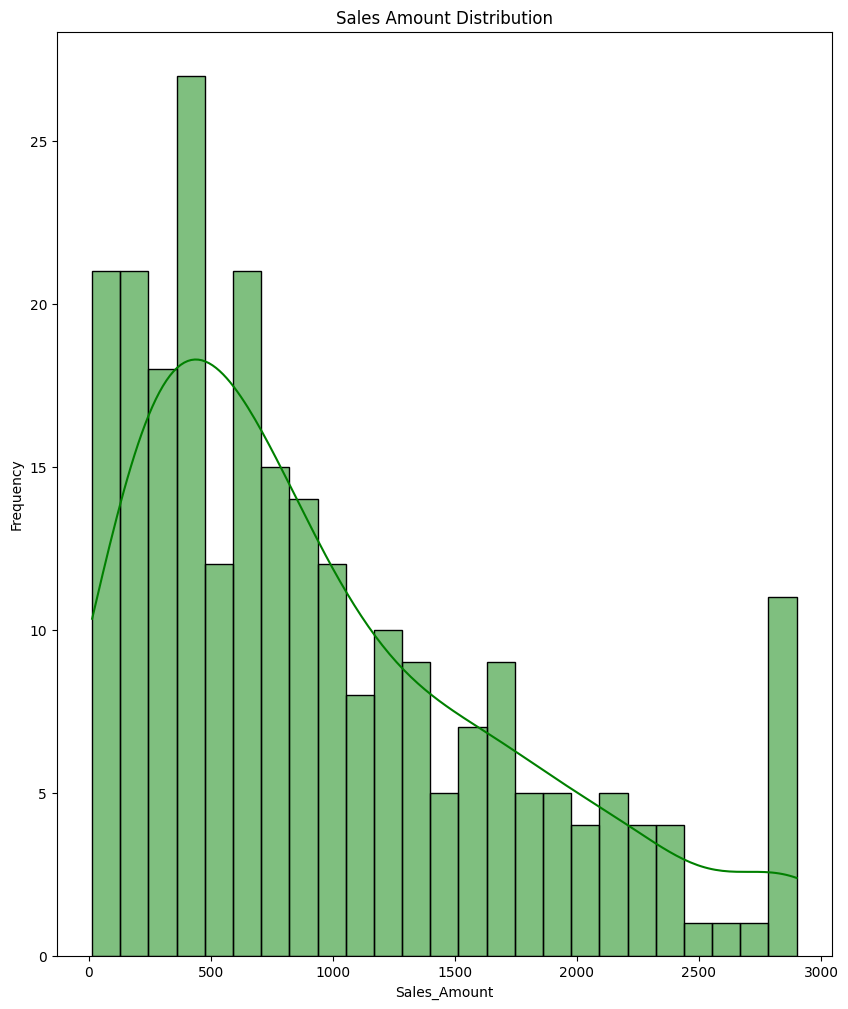

In [70]:
plt.figure(figsize=(10,12))
sb.histplot(data = df, x = "sales_amount",bins = 25,kde = True,color = "Green")
plt.title("Sales Amount Distribution")
plt.xlabel("Sales_Amount")
plt.ylabel("Frequency")
plt.show()

#Observation - the amount of 500 sold most

In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 0 to 249
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   transaction_id  250 non-null    string        
 1   region          250 non-null    category      
 2   product_id      250 non-null    int64         
 3   sales_amount    250 non-null    float64       
 4   date            250 non-null    datetime64[ns]
 5   units_sold      250 non-null    float64       
 6   unit_price      250 non-null    float64       
 7   discount_pct    250 non-null    float64       
 8   store_id        250 non-null    object        
dtypes: category(1), datetime64[ns](1), float64(4), int64(1), object(1), string(1)
memory usage: 26.1+ KB


#Using count plot for frequency of transactions per region

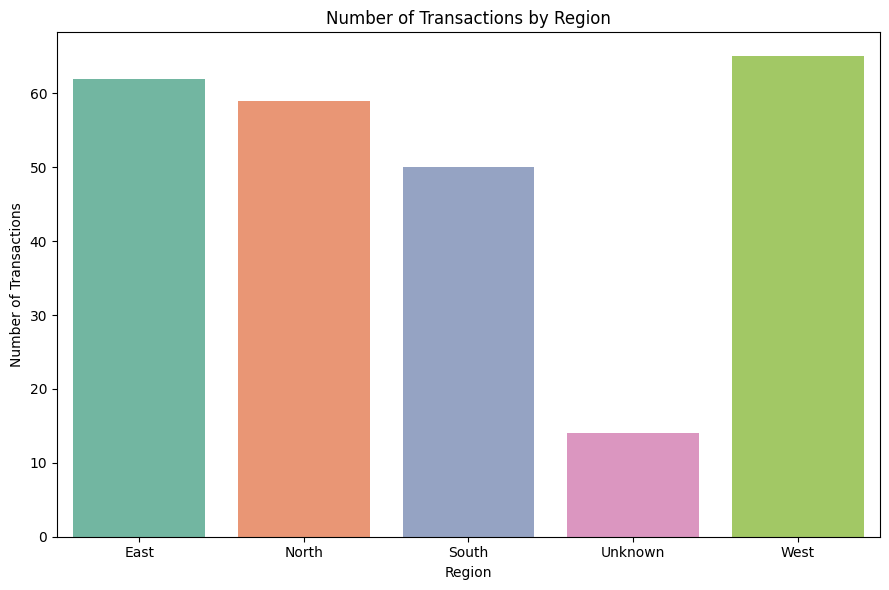

In [74]:
plt.figure(figsize=(9, 6))
sb.countplot(
    data=df,
    x='region',
    hue='region',
    palette='Set2',
    legend=False
)
plt.title('Number of Transactions by Region')
plt.xlabel('Region')
plt.ylabel('Number of Transactions')
plt.tight_layout()
plt.show()

#Observation -The west region has participated in more transactions

#Using box plot for discount percentage and also helpful for finding outliers

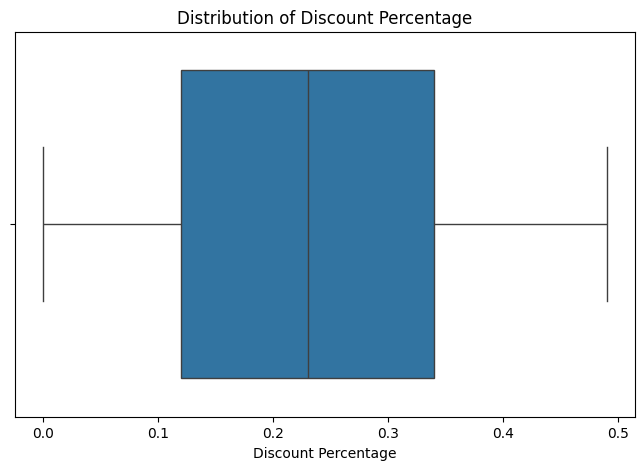

In [76]:
plt.figure(figsize=(8, 5))
sb.boxplot(data=df, x='discount_pct')
plt.title('Distribution of Discount Percentage')
plt.xlabel('Discount Percentage')
plt.show()

#Observation - The median lies in the quartile of 0.5

#Bivariate analysis is performed for relations for multiple data columns


#Pie chart disrtibutes the categories as per disrtibutions

In [97]:
import plotly.express as px
store_transactions = df['store_id'].value_counts().reset_index()
store_transactions.columns = ['store_id', 'transaction_count']
fig = px.pie(
    store_transactions,
    names='store_id',
    values='transaction_count',
    title='Transaction Share by Store',
    hole=0.3
)
fig.show()

#Observation -The Store S2 has more Transaction share 24.8%


#Performing scatter plot unit price vs units sold by region so that we can find that how many units sold and for what price and for which region..

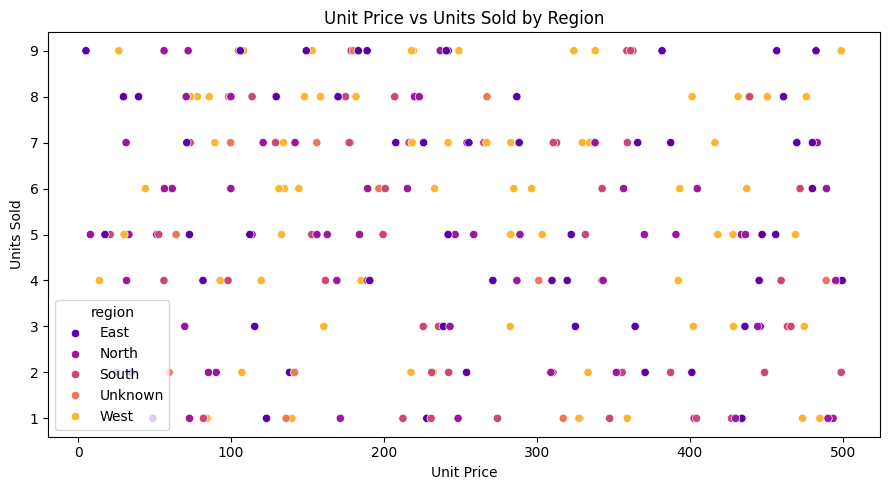

In [82]:
plt.figure(figsize=(9, 5))
sb.scatterplot(
    data=df,
    x='unit_price',
    y='units_sold',
    hue='region',
    palette='plasma'
)
plt.title('Unit Price vs Units Sold by Region')
plt.xlabel('Unit Price')
plt.ylabel('Units Sold')
plt.tight_layout()
plt.show()


#Observation -East Region has more units sold and for least unit cost of 250

#We use bar chart for comparing the total units sold in each region.

In [95]:
import plotly.express as px
store_price = df.groupby('store_id', observed=True)['unit_price'].mean().reset_index()
fig = px.bar(
    store_price,
    x='store_id',
    y='unit_price',
    color='store_id',
    text_auto='.2f',
    title='Average Unit Price by Store',
    template='plotly_white'
)
fig.show()

#Observation -The Store S has more Average unit price


#Using line plot for showing how the number of units sold changes over time.

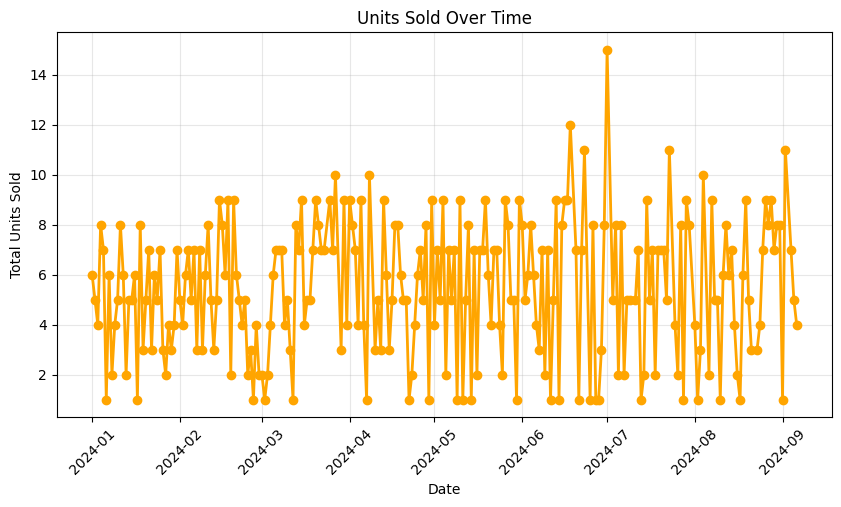

In [88]:
import matplotlib.pyplot as plt
daily_sales = df.groupby('date')['units_sold'].sum().reset_index()
plt.figure(figsize=(10, 5))
plt.plot(daily_sales['date'], daily_sales['units_sold'],
         marker='o', linewidth=2,color = "orange")
plt.title('Units Sold Over Time')
plt.xlabel('Date')
plt.ylabel('Total Units Sold')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

#Observation -On the date if 2024-07 the more units sold

#Multivariate analysis is a statistical technique used to analyse three or more variables simultaneously to understand relationships, patterns, trends and dependencies among them.

#HeatMap shows the correlation between the columns.

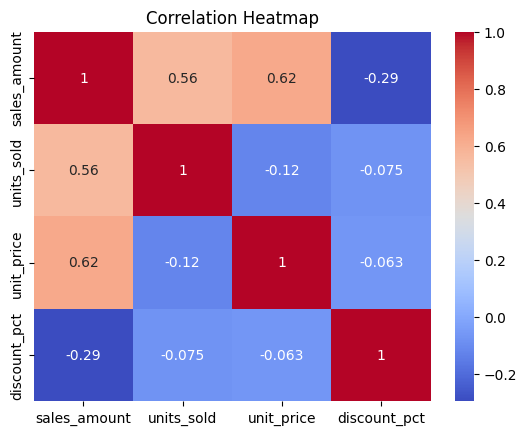

In [89]:
sb.heatmap(df[['sales_amount', 'units_sold', 'unit_price', 'discount_pct']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

#A pair plot displays relationships between multiple numerical variables. It shows scatter plots between variable pairs and distributions along the diagonal.

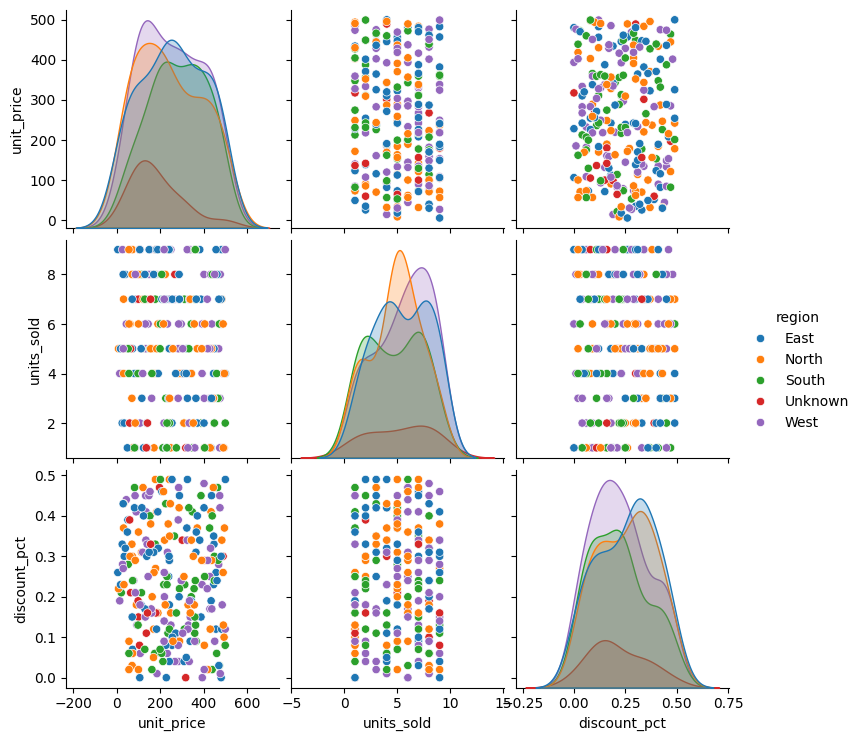

In [93]:
sb.pairplot(df, vars=['unit_price', 'units_sold', 'discount_pct'], hue='region')
plt.show()

'''FINAL PROJECT REPORT :
The Sales Transaction Data Analysis project focuses on analysing sales data using Python. The dataset was cleaned by handling missing values, removing duplicate records and correcting inconsistent data types. Outlier detection was performed using the IQR method. Univariate analysis was used to understand individual variable distributions, while bivariate analysis explored relationships between different variables. Multivariate analysis was performed using correlation heatmaps, pair plots and bubble charts. Different visualizations were created using Matplotlib, Seaborn and Plotly. Overall, this project helped identify sales patterns, understand transaction behaviour and gain practical experience in data preprocessing and exploratory data analysis.'''